In [27]:
import pandas as pd

df = pd.read_csv("../Data/raw/all_players_metrics.csv")

In [28]:
df.shape

(50, 56)

In [29]:
df.columns.tolist()


['Player ID',
 'Starts',
 'Appearances',
 'Minutes',
 'Subbed on',
 'Subbed off',
 'On-pitch goal difference',
 'Goals',
 'Shots',
 'Shots on target',
 'Shots on target %',
 'Free kicks scored',
 'Penalties scored',
 'Penalties taken',
 'Headed shots',
 'xGoals',
 'Non-pen xGoals',
 'Assists',
 'Key passes',
 'Chances created',
 'Passes completed',
 'Pass completion %',
 'Line-breaking passes',
 'Through ball passes completed',
 'Balls over the top completed',
 'Crosses attempted',
 'Crosses completed',
 'Crossing accuracy %',
 'Crosses into dangerous area',
 'Dribbles completed',
 'Successful dribble %',
 'Fouls won',
 'Successful ball carries',
 'Tackles faced won',
 '50/50 duels won',
 'Aerial duels won',
 'Dribbles faced won',
 'Tackles won',
 'Clean sheets',
 'Goals conceded while on pitch',
 'Interceptions',
 'Cross interceptions',
 'Total pressures',
 'Positional mistakes',
 'Blocks',
 'Clearances',
 '% Miscontrols',
 'Possessions',
 'Line-breaking passes received',
 'Possession

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 56 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Player ID                      50 non-null     int64  
 1   Starts                         50 non-null     int64  
 2   Appearances                    50 non-null     int64  
 3   Minutes                        50 non-null     int64  
 4   Subbed on                      50 non-null     int64  
 5   Subbed off                     50 non-null     int64  
 6   On-pitch goal difference       50 non-null     int64  
 7   Goals                          50 non-null     int64  
 8   Shots                          50 non-null     int64  
 9   Shots on target                50 non-null     int64  
 10  Shots on target %              48 non-null     float64
 11  Free kicks scored              50 non-null     int64  
 12  Penalties scored               50 non-null     int64  
 13  Pen

In [31]:
#Cleaning Phase


In [32]:
missing_values = df.isna().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print(missing_values)

Successful dribble %    5
Crossing accuracy %     3
Shots on target %       2
dtype: int64


In [33]:
missing_rows = df[df.isna().any(axis=1)]

print(missing_rows)

    Player ID  Starts  Appearances  Minutes  Subbed on  Subbed off  \
8    21045321       4            4      395          0           1   
14     262324       4            4      399          0           1   
20   31238688       3            3      305          0           0   
32   37391576       1            1      101          0           0   
34   37551076       2            3      207          1           1   
39    5270371       4            4      410          0           0   
49      96959       2            3      195          1           2   

    On-pitch goal difference  Goals  Shots  Shots on target  ...  \
8                          4      0      0                0  ...   
14                         5      0      0                0  ...   
20                         3      1      1                1  ...   
32                        -3      1      2                1  ...   
34                         2      1      3                1  ...   
39                         6   

In [34]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate player IDs:", df["Player ID"].duplicated().sum())

Dataset shape: (50, 56)

Column data types:
Player ID                          int64
Starts                             int64
Appearances                        int64
Minutes                            int64
Subbed on                          int64
Subbed off                         int64
On-pitch goal difference           int64
Goals                              int64
Shots                              int64
Shots on target                    int64
Shots on target %                float64
Free kicks scored                  int64
Penalties scored                   int64
Penalties taken                    int64
Headed shots                       int64
xGoals                           float64
Non-pen xGoals                   float64
Assists                            int64
Key passes                         int64
Chances created                    int64
Passes completed                   int64
Pass completion %                  int64
Line-breaking passes               int64
Through ball 

In [35]:
print("Minimum value in each numeric column:")
print(df.min(numeric_only=True))

print("\nMaximum value in each numeric column:")
print(df.max(numeric_only=True))

Minimum value in each numeric column:
Player ID                        268.0
Starts                             1.0
Appearances                        1.0
Minutes                          101.0
Subbed on                          0.0
Subbed off                         0.0
On-pitch goal difference          -6.0
Goals                              0.0
Shots                              0.0
Shots on target                    0.0
Shots on target %                  0.0
Free kicks scored                  0.0
Penalties scored                   0.0
Penalties taken                    0.0
Headed shots                       0.0
xGoals                             0.0
Non-pen xGoals                     0.0
Assists                            0.0
Key passes                         0.0
Chances created                    0.0
Passes completed                  37.0
Pass completion %                 70.0
Line-breaking passes               4.0
Through ball passes completed      0.0
Balls over the top complet

In [36]:
print(
    "Shots on target greater than shots:",
    (df["Shots on target"] > df["Shots"]).sum()
)

print(
    "Goals greater than shots on target:",
    (df["Goals"] > df["Shots on target"]).sum()
)

print(
    "Subbed on greater than appearances:",
    (df["Subbed on"] > df["Appearances"]).sum()
)

print(
    "Subbed off greater than appearances:",
    (df["Subbed off"] > df["Appearances"]).sum()
)

print(
    "Crosses completed greater than attempted:",
    (df["Crosses completed"] > df["Crosses attempted"]).sum()
)

Shots on target greater than shots: 0
Goals greater than shots on target: 5
Subbed on greater than appearances: 0
Subbed off greater than appearances: 0
Crosses completed greater than attempted: 0


In [37]:
df.loc[
    df["Goals"] > df["Shots on target"],
    ["Player ID", "Goals", "Shots", "Shots on target"]
]

,Player ID,Goals,Shots,Shots on target
22,32362,1,4,0
24,33186829,2,6,1
30,37317434,4,10,3
35,37562127,2,2,1
36,37581992,2,3,1


In [38]:
print("Penalties scored greater than penalties taken:",
      (df["Penalties scored"] > df["Penalties taken"]).sum())

print("Crosses into dangerous area greater than crosses attempted:",
      (df["Crosses into dangerous area"] > df["Crosses attempted"]).sum())

print("Subbed off greater than starts:",
      (df["Subbed off"] > df["Starts"]).sum())

Penalties scored greater than penalties taken: 5
Crosses into dangerous area greater than crosses attempted: 0
Subbed off greater than starts: 0


In [39]:
df.loc[
    df["Penalties scored"] > df["Penalties taken"],
    ["Player ID", "Goals", "Penalties scored", "Penalties taken"]
]

,Player ID,Goals,Penalties scored,Penalties taken
6,1887,2,2,1
22,32362,1,1,0
24,33186829,2,1,0
30,37317434,4,1,0
35,37562127,2,1,0


In [40]:
''' Our validation results so far:
- No issue found: Shots on target vs. shots, substitutions vs. appearances, crosses completed vs. attempted, and crosses into dangerous areas vs. crosses attempted.
- Explained by differing definitions: Goals vs. shots on target, and penalties scored vs. penalties taken.
- Missing percentage values: Preserved as NaN because the percentages can be undefined.'''

' Our validation results so far:\n- No issue found: Shots on target vs. shots, substitutions vs. appearances, crosses completed vs. attempted, and crosses into dangerous areas vs. crosses attempted.\n- Explained by differing definitions: Goals vs. shots on target, and penalties scored vs. penalties taken.\n- Missing percentage values: Preserved as NaN because the percentages can be undefined.'

In [41]:
print("Yellow cards greater than appearances:",
      (df["Yellow cards"] > df["Appearances"]).sum())

print("Red cards greater than appearances:",
      (df["Red cards"] > df["Appearances"]).sum())

print("Straight red cards greater than red cards:",
      (df["Straight red cards"] > df["Red cards"]).sum())

Yellow cards greater than appearances: 0
Red cards greater than appearances: 0
Straight red cards greater than red cards: 0


In [42]:
print("Pass completion % outside 0–100:",
      ((df["Pass completion %"] < 0) |
       (df["Pass completion %"] > 100)).sum())

print("Shots on target % outside 0–100:",
      ((df["Shots on target %"] < 0) |
       (df["Shots on target %"] > 100)).sum())

print("Crossing accuracy % outside 0–100:",
      ((df["Crossing accuracy %"] < 0) |
       (df["Crossing accuracy %"] > 100)).sum())

print("Successful dribble % outside 0–100:",
      ((df["Successful dribble %"] < 0) |
       (df["Successful dribble %"] > 100)).sum())

Pass completion % outside 0–100: 0
Shots on target % outside 0–100: 0
Crossing accuracy % outside 0–100: 0
Successful dribble % outside 0–100: 0


In [43]:
#Cleaning Done
#Next Choosing the analysis questions

In [44]:
for col in df.columns:
    print(col)

Player ID
Starts
Appearances
Minutes
Subbed on
Subbed off
On-pitch goal difference
Goals
Shots
Shots on target
Shots on target %
Free kicks scored
Penalties scored
Penalties taken
Headed shots
xGoals
Non-pen xGoals
Assists
Key passes
Chances created
Passes completed
Pass completion %
Line-breaking passes
Through ball passes completed
Balls over the top completed
Crosses attempted
Crosses completed
Crossing accuracy %
Crosses into dangerous area
Dribbles completed
Successful dribble %
Fouls won
Successful ball carries
Tackles faced won
50/50 duels won
Aerial duels won
Dribbles faced won
Tackles won
Clean sheets
Goals conceded while on pitch
Interceptions
Cross interceptions
Total pressures
Positional mistakes
Blocks
Clearances
% Miscontrols
Possessions
Line-breaking passes received
Possessions in penalty area
Cross targets
Yellow cards
Red cards
Straight red cards
Fouls committed
Penalties conceded


In [45]:
df.describe().T  

,count,mean,std,min,25%,50%,75%,max
Player ID,50.0,1.218011e+07,1.598359e+07,268.0,96304.00,326570.0,29637394.75,37581992.0
Starts,50.0,4.320000e+00,1.531173e+00,1.0,4.00,4.0,5.00,8.0
Appearances,50.0,4.940000e+00,1.671001e+00,1.0,4.00,5.0,6.00,8.0
Minutes,50.0,4.329800e+02,1.546145e+02,101.0,330.50,410.5,536.50,825.0
Subbed on,50.0,6.200000e-01,1.210330e+00,0.0,0.00,0.0,1.00,7.0
Subbed off,50.0,2.020000e+00,1.571299e+00,0.0,1.00,2.0,3.00,6.0
On-pitch goal difference,50.0,3.280000e+00,3.659151e+00,-6.0,1.00,3.5,5.75,12.0
Goals,50.0,8.400000e-01,1.314907e+00,0.0,0.00,0.0,1.00,7.0
Shots,50.0,5.860000e+00,4.295275e+00,0.0,3.00,5.0,8.00,20.0
Shots on target,50.0,1.780000e+00,2.053270e+00,0.0,1.00,1.0,3.00,13.0


In [46]:
players_df = pd.read_csv("../Data/raw/world_cup_50_players.csv")

In [47]:
# Extract the numeric player ID from each URL
players_df["Player ID"] = (
    players_df["URL"].str.extract(r"/player/(\d+)")
)

# Create a mapping from player ID to player name
player_map = dict(zip(players_df["Player ID"], players_df["Player"]))

# Replace IDs in my existing DataFrame with player names
df["Player ID"] = df["Player ID"].astype(str).map(player_map)

# Rename the column
df.rename(columns={"Player ID": "Player"}, inplace=True)


In [48]:
df

,Player,Starts,Appearances,Minutes,Subbed on,Subbed off,On-pitch goal difference,Goals,Shots,Shots on target,...,% Miscontrols,Possessions,Line-breaking passes received,Possessions in penalty area,Cross targets,Yellow cards,Red cards,Straight red cards,Fouls committed,Penalties conceded
0,Leandro Paredes,4,7,561,3,2,3,0,4,1,...,0,594,19,3,0,2,0,0,9,0
1,Bruno Fernandes,5,5,475,0,1,3,0,9,3,...,0,333,42,14,3,0,0,0,2,0
2,Rodrigo De Paul,6,7,547,1,5,5,0,2,1,...,0,365,26,2,2,1,0,0,2,0
3,Kevin De Bruyne,5,5,416,0,5,1,1,20,4,...,10,238,20,22,3,1,0,0,2,0
4,Patrick Berg,4,6,523,2,0,-1,0,3,0,...,0,209,23,7,3,1,0,0,4,0
5,Rodri,8,8,825,0,2,12,0,7,0,...,0,846,47,8,7,0,0,0,11,0
6,Granit Xhaka,6,6,692,0,0,5,2,9,2,...,0,519,55,5,0,2,0,0,5,0
7,Denis Zakaria,4,4,395,0,3,2,0,4,1,...,0,222,9,9,4,2,0,0,4,0
8,Érik Lira,4,4,395,0,1,4,0,0,0,...,0,216,19,2,0,0,0,0,3,0
9,Azzedine Ounahi,5,6,482,1,4,2,2,5,3,...,10,353,27,10,0,1,0,0,3,0


In [49]:
# Calculate 90-minute units
df["Minutes_per_90"] = df["Minutes"] / 90

# Metrics to convert to per 90 minutes
per90_columns = [
    # Shooting
    "Goals",
    "Shots",
    "Shots on target",
    "Free kicks scored",
    "Penalties scored",
    "Headed shots",
    "xGoals",
    "Non-pen xGoals",

    # Creativity and passing
    "Assists",
    "Key passes",
    "Chances created",
    "Passes completed",
    "Line-breaking passes",
    "Through ball passes completed",
    "Balls over the top completed",
    "Line-breaking passes received",

    # Crossing
    "Crosses attempted",
    "Crosses completed",
    "Crosses into dangerous area",
    "Cross targets",

    # Dribbling and possession
    "Dribbles completed",
    "Successful ball carries",
    "Possessions",
    "Possessions in penalty area",

    # Defending and duels
    "Tackles faced won",
    "50/50 duels won",
    "Aerial duels won",
    "Dribbles faced won",
    "Tackles won",
    "Interceptions",
    "Cross interceptions",
    "Total pressures",
    "Blocks",
    "Clearances",

    # Discipline and match impact
    "Fouls won",
    "Fouls committed",
    "Penalties conceded",
    "Yellow cards",
    "Red cards",
    "Straight red cards",
    "Goals conceded while on pitch"
]

# Create per-90 columns
for col in per90_columns:
    df[f"{col}_per_90"] = df[col] / df["Minutes_per_90"]

In [50]:
#Next EDA

In [51]:
top_goals = df.sort_values(
    by="Goals",
    ascending=False
)[["Player", "Minutes", "Goals", "Goals_per_90"]].head(10)

top_goals

,Player,Minutes,Goals,Goals_per_90
27,Jude Bellingham,704,7,0.894886
30,Ismael Saibari,430,4,0.837209
41,Elijah Just,293,3,0.921502
11,Malik Tillman,417,2,0.431655
36,Habib Diarra,172,2,1.046512
24,Jamal Musiala,326,2,0.552147
19,Enzo Fernández,762,2,0.236220
35,Matías Galarza,458,2,0.393013
6,Granit Xhaka,692,2,0.260116
43,Youri Tielemans,541,2,0.332717


In [52]:
df.shape

(50, 98)

In [53]:
df.columns.tolist()

['Player',
 'Starts',
 'Appearances',
 'Minutes',
 'Subbed on',
 'Subbed off',
 'On-pitch goal difference',
 'Goals',
 'Shots',
 'Shots on target',
 'Shots on target %',
 'Free kicks scored',
 'Penalties scored',
 'Penalties taken',
 'Headed shots',
 'xGoals',
 'Non-pen xGoals',
 'Assists',
 'Key passes',
 'Chances created',
 'Passes completed',
 'Pass completion %',
 'Line-breaking passes',
 'Through ball passes completed',
 'Balls over the top completed',
 'Crosses attempted',
 'Crosses completed',
 'Crossing accuracy %',
 'Crosses into dangerous area',
 'Dribbles completed',
 'Successful dribble %',
 'Fouls won',
 'Successful ball carries',
 'Tackles faced won',
 '50/50 duels won',
 'Aerial duels won',
 'Dribbles faced won',
 'Tackles won',
 'Clean sheets',
 'Goals conceded while on pitch',
 'Interceptions',
 'Cross interceptions',
 'Total pressures',
 'Positional mistakes',
 'Blocks',
 'Clearances',
 '% Miscontrols',
 'Possessions',
 'Line-breaking passes received',
 'Possessions i

In [54]:

category_map = {
    "Goal Threat & Finishing": [
        "Goals_per_90",
        "Shots_per_90",
        "Shots on target_per_90",
        "Shots on target %",
        "Penalties scored_per_90",
        "Free kicks scored_per_90",
        "Headed shots_per_90",
        "xGoals_per_90",
        "Non-pen xGoals_per_90"
    ],

    "Attacking Positioning": [
        "Possessions in penalty area_per_90",
        "Line-breaking passes received_per_90",
        "Cross targets_per_90"
    ],

    "Creativity": [
        "Assists_per_90",
        "Key passes_per_90",
        "Chances created_per_90",
        "Line-breaking passes_per_90",
    ],

    "Passing & Progression": [
        "Passes completed_per_90",
        "Pass completion %",
        "Through ball passes completed_per_90",
        "Balls over the top completed_per_90"
    ],

    "Crossing & Wide Delivery": [
        "Crosses attempted_per_90",
        "Crosses completed_per_90",
        "Crossing accuracy %",
        "Crosses into dangerous area_per_90" 
    ],

    "Ball Carrying & Dribbling": [
        "Dribbles completed_per_90",
        "Successful dribble %",
        "Successful ball carries_per_90",
        "Tackles faced won_per_90",
        "Fouls won_per_90",
        "% Miscontrols",
    ],

    "Defensive Contributions": [
        "Tackles won_per_90",
        "50/50 duels won_per_90",
        "Aerial duels won_per_90",
        "Dribbles faced won_per_90",
        "Interceptions_per_90",
        "Cross interceptions_per_90",
        "Total pressures_per_90",
        "Blocks_per_90",
        "Clearances_per_90",
        "Positional mistakes",
        "Penalties conceded_per_90"
    ],

    "Discipline": [
        "Fouls committed_per_90",
        "Yellow cards_per_90",
        "Red cards_per_90",
        "Straight red cards_per_90"
    ]
}


In [55]:
for category, stats in category_map.items():
    print(category, ":", len(stats))

Goal Threat & Finishing : 9
Attacking Positioning : 3
Creativity : 4
Passing & Progression : 4
Crossing & Wide Delivery : 4
Ball Carrying & Dribbling : 6
Defensive Contributions : 11
Discipline : 4


In [56]:
for category, stats in category_map.items():
    print("\n" + category)
    print("-" * len(category))
    for stat in stats:
        print(stat)


Goal Threat & Finishing
-----------------------
Goals_per_90
Shots_per_90
Shots on target_per_90
Shots on target %
Penalties scored_per_90
Free kicks scored_per_90
Headed shots_per_90
xGoals_per_90
Non-pen xGoals_per_90

Attacking Positioning
---------------------
Possessions in penalty area_per_90
Line-breaking passes received_per_90
Cross targets_per_90

Creativity
----------
Assists_per_90
Key passes_per_90
Chances created_per_90
Line-breaking passes_per_90

Passing & Progression
---------------------
Passes completed_per_90
Pass completion %
Through ball passes completed_per_90
Balls over the top completed_per_90

Crossing & Wide Delivery
------------------------
Crosses attempted_per_90
Crosses completed_per_90
Crossing accuracy %
Crosses into dangerous area_per_90

Ball Carrying & Dribbling
-------------------------
Dribbles completed_per_90
Successful dribble %
Successful ball carries_per_90
Tackles faced won_per_90
Fouls won_per_90
% Miscontrols

Defensive Contributions
------

In [57]:
higher_is_better = [
    "Goals_per_90",
    "Shots_per_90",
    "Shots on target_per_90",
    "Shots on target %",
    "Penalties scored_per_90",
    "Free kicks scored_per_90",
    "Headed shots_per_90",
    "xGoals_per_90",
    "Non-pen xGoals_per_90",

    "Possessions in penalty area_per_90",
    "Line-breaking passes received_per_90",
    "Cross targets_per_90",

    "Assists_per_90",
    "Key passes_per_90",
    "Chances created_per_90",
    "Line-breaking passes_per_90",

    "Passes completed_per_90",
    "Pass completion %",
    "Through ball passes completed_per_90",
    "Balls over the top completed_per_90",

    "Crosses attempted_per_90",
    "Crosses completed_per_90",
    "Crossing accuracy %",
    "Crosses into dangerous area_per_90",

    "Dribbles completed_per_90",
    "Successful dribble %",
    "Successful ball carries_per_90",
    "Tackles faced won_per_90",
    "Fouls won_per_90",

    "Tackles won_per_90",
    "50/50 duels won_per_90",
    "Aerial duels won_per_90",
    "Dribbles faced won_per_90",
    "Interceptions_per_90",
    "Cross interceptions_per_90",
    "Total pressures_per_90",
    "Blocks_per_90",
    "Clearances_per_90",

    
]

In [58]:
lower_is_better = [
    "% Miscontrols",
    "Positional mistakes",
    "Penalties conceded_per_90",
    "Fouls committed_per_90",
    "Yellow cards_per_90",
    "Red cards_per_90",
    "Straight red cards_per_90"
]

In [59]:
print("Higher is better:", len(higher_is_better))
print("Lower is better:", len(lower_is_better))


Higher is better: 38
Lower is better: 7


In [60]:
#New Df that will host all the scores of the Individual metrics

score_df=df.copy()

In [61]:
score_df["Minutes"].describe()

count     50.000000
mean     432.980000
std      154.614529
min      101.000000
25%      330.500000
50%      410.500000
75%      536.500000
max      825.000000
Name: Minutes, dtype: float64

In [62]:
'''Why 300 minutes specifically?
300 minutes is equivalent to approximately 3⅓ full 90-minute matches. It is a practical minimum threshold for this project, but it is not a universal scientific cutoff. Football analytics commonly uses minimum-minute thresholds to reduce misleading rankings from small samples, and the appropriate threshold depends on the competition and metrics being analyzed. 
Soccer Analytics+1


For my project, the justification is:
- Reduce small-sample bias: limit extreme per-90 values caused by very little playing time.
- Improve comparison fairness: compare players with a minimum amount of observed match performance.
- Preserve a useful sample: avoid setting the threshold so high that too many midfielders are excluded from the cost-efficiency analysis.'''

'Why 300 minutes specifically?\n300 minutes is equivalent to approximately 3⅓ full 90-minute matches. It is a practical minimum threshold for this project, but it is not a universal scientific cutoff. Football analytics commonly uses minimum-minute thresholds to reduce misleading rankings from small samples, and the appropriate threshold depends on the competition and metrics being analyzed. \nSoccer Analytics+1\n\n\nFor my project, the justification is:\n- Reduce small-sample bias: limit extreme per-90 values caused by very little playing time.\n- Improve comparison fairness: compare players with a minimum amount of observed match performance.\n- Preserve a useful sample: avoid setting the threshold so high that too many midfielders are excluded from the cost-efficiency analysis.'

In [63]:
thresholds = [300, 450, 600, 750]

for minutes in thresholds:
    count = (score_df["Minutes"] >= minutes).sum()
    print(f"{minutes}+ minutes: {count} players")

300+ minutes: 41 players
450+ minutes: 18 players
600+ minutes: 7 players
750+ minutes: 2 players


In [64]:
score_df.loc[
    score_df["Minutes"] < 300,
    ["Player", "Minutes"]
].sort_values("Minutes")

,Player,Minutes
32,Thelo Aasgaard,101
36,Habib Diarra,172
49,Houssem Aouar,195
34,Nathan Saliba,207
10,Lucas Paquetá,257
23,Mikel Merino,264
13,Federico Valverde,275
21,In-beom Hwang,289
41,Elijah Just,293


In [65]:
score_df = score_df[
    score_df["Minutes"] >= 300
].copy()

print("Remaining players:", len(score_df))
print("Minimum minutes:", score_df["Minutes"].min())

Remaining players: 41
Minimum minutes: 303


In [66]:
#These are the equations for calculating the score of individual metrics which will further combine to create the category score for each player 

for col in higher_is_better:
    score_df[col + "_score"] = (
        score_df[col].rank(pct=True) * 100
    )

for col in lower_is_better:
    score_df[col + "_score"] = (
        (1 - score_df[col].rank(pct=True)) * 100
    )

In [67]:
goal_threat_weights = {
    "Goals_per_90": 0.20,
    "Shots_per_90": 0.10,
    "Shots on target_per_90": 0.10,
    "Shots on target %": 0.10,
    "Penalties scored_per_90": 0.05,
    "Free kicks scored_per_90": 0.05,
    "Headed shots_per_90": 0.05,
    "xGoals_per_90": 0.20,
    "Non-pen xGoals_per_90": 0.15
}

print(sum(goal_threat_weights.values()))

1.0


In [68]:
attacking_positioning_weights = {
    "Possessions in penalty area_per_90": 0.45,
    "Line-breaking passes received_per_90": 0.35,
    "Cross targets_per_90": 0.20
}

print(sum(attacking_positioning_weights.values()))

1.0


In [69]:
creativity_weights = {
    "Assists_per_90": 0.25,
    "Key passes_per_90": 0.25,
    "Chances created_per_90": 0.30,
    "Line-breaking passes_per_90": 0.20
}

print(sum(creativity_weights.values()))

1.0


In [70]:
passing_progression_weights = {
    "Passes completed_per_90": 0.30,
    "Pass completion %": 0.25,
    "Through ball passes completed_per_90": 0.25,
    "Balls over the top completed_per_90": 0.20
}

print(sum(passing_progression_weights.values()))

1.0


In [71]:
crossing_wide_delivery_weights = {
    "Crosses attempted_per_90": 0.15,
    "Crosses completed_per_90": 0.30,
    "Crossing accuracy %": 0.25,
    "Crosses into dangerous area_per_90": 0.30
}

In [72]:
ball_carrying_dribbling_weights = {
    "Dribbles completed_per_90": 0.30,
    "Successful dribble %": 0.25,
    "Successful ball carries_per_90": 0.25,
    "Tackles faced won_per_90": 0.10,
    "% Miscontrols": 0.10
}

In [73]:
defensive_contributions_weights = {
    "Tackles won_per_90": 0.20,
    "50/50 duels won_per_90": 0.10,
    "Aerial duels won_per_90": 0.10,
    "Dribbles faced won_per_90": 0.15,
    "Interceptions_per_90": 0.20,
    "Cross interceptions_per_90": 0.05,
    "Total pressures_per_90": 0.10,
    "Blocks_per_90": 0.05,
    "Clearances_per_90": 0.05
}

In [74]:
discipline_weights = {
    "Fouls committed_per_90": 0.20,
    "Yellow cards_per_90": 0.20,
    "Red cards_per_90": 0.25,
    "Straight red cards_per_90": 0.35
}

In [75]:
category_weights = {
    "Goal Threat & Finishing": goal_threat_weights,
    "Attacking Positioning": attacking_positioning_weights,
    "Creativity": creativity_weights,
    "Passing & Progression": passing_progression_weights,
    "Crossing & Wide Delivery": crossing_wide_delivery_weights,
    "Ball Carrying & Dribbling": ball_carrying_dribbling_weights,
    "Defensive Contributions": defensive_contributions_weights,
    "Discipline": discipline_weights
}

In [76]:
for category, weights in category_weights.items():
    weighted_scores = sum(
        score_df[stat + "_score"].fillna(0) * weight
        for stat, weight in weights.items()
    )

    available_weights = sum(
        score_df[stat + "_score"].notna() * weight
        for stat, weight in weights.items()
    )

    score_df[category + "_Score"] = (
        weighted_scores / available_weights
    ).where(available_weights != 0)

In [77]:
score_df[
    [
        "Player",
        "Goal Threat & Finishing_Score",
        "Attacking Positioning_Score",
        "Creativity_Score",
        "Passing & Progression_Score",
        "Ball Carrying & Dribbling_Score",
        "Defensive Contributions_Score",
        "Discipline_Score"
    ]
]

,Player,Goal Threat & Finishing_Score,Attacking Positioning_Score,Creativity_Score,Passing & Progression_Score,Ball Carrying & Dribbling_Score,Defensive Contributions_Score,Discipline_Score
0,Leandro Paredes,30.958412,22.317073,47.317073,60.304878,57.153402,47.439024,32.195122
1,Bruno Fernandes,64.129143,79.634146,52.195122,73.475610,26.911104,49.512195,61.951220
2,Rodrigo De Paul,33.900876,30.365854,49.878049,64.939024,53.129012,38.780488,55.121951
3,Kevin De Bruyne,77.071607,75.731707,62.317073,47.012195,32.398909,31.219512,51.219512
4,Patrick Berg,25.855222,50.975610,35.487805,31.646341,58.879974,51.219512,47.317073
5,Rodri,37.196685,57.195122,56.829268,78.597561,41.830873,72.073171,49.268293
6,Granit Xhaka,60.974046,45.731707,27.682927,69.451220,62.167843,41.219512,43.902439
7,Denis Zakaria,57.787680,55.121951,16.463415,31.402439,64.029204,60.731707,37.560976
8,Érik Lira,19.512195,28.902439,47.804878,39.451220,32.764228,34.878049,55.609756
9,Azzedine Ounahi,64.548155,58.902439,60.121951,74.573171,63.482028,26.829268,50.731707


In [78]:
role_weights = {
    "Defensive Midfielder": {
        "Goal Threat & Finishing": 0.05,
        "Attacking Positioning": 0.05,
        "Creativity": 0.10,
        "Passing & Progression": 0.225,
        "Crossing & Wide Delivery": 0.05,
        "Ball Carrying & Dribbling": 0.10,
        "Defensive Contributions": 0.375,
        "Discipline": 0.05
    },

    "Box-to-Box Midfielder": {
        "Goal Threat & Finishing": 0.125,
        "Attacking Positioning": 0.125,
        "Creativity": 0.15,
        "Passing & Progression": 0.15,
        "Crossing & Wide Delivery": 0.075,
        "Ball Carrying & Dribbling": 0.15,
        "Defensive Contributions": 0.175,
        "Discipline": 0.05
    },

    "Attacking Midfielder": {
        "Goal Threat & Finishing": 0.225,
        "Attacking Positioning": 0.175,
        "Creativity": 0.225,
        "Passing & Progression": 0.10,
        "Crossing & Wide Delivery": 0.10,
        "Ball Carrying & Dribbling": 0.125,
        "Defensive Contributions": 0.025,
        "Discipline": 0.025
    }
}

In [79]:
for role, weights in role_weights.items():
    print(role, sum(weights.values()))

Defensive Midfielder 1.0
Box-to-Box Midfielder 1.0
Attacking Midfielder 1.0


In [80]:
score_df["Defensive_Midfielder_Score"] = sum(
    score_df[category + "_Score"] * weight
    for category, weight in role_weights["Defensive Midfielder"].items()
)

score_df["Box_to_Box_Midfielder_Score"] = sum(
    score_df[category + "_Score"] * weight
    for category, weight in role_weights["Box-to-Box Midfielder"].items()
)

score_df["Attacking_Midfielder_Score"] = sum(
    score_df[category + "_Score"] * weight
    for category, weight in role_weights["Attacking Midfielder"].items()
)


In [81]:
score_df[
    [
        "Player",
        "Defensive_Midfielder_Score",
        "Box_to_Box_Midfielder_Score",
        "Attacking_Midfielder_Score"
    ]
]

,Player,Defensive_Midfielder_Score,Box_to_Box_Midfielder_Score,Attacking_Midfielder_Score
0,Leandro Paredes,47.768215,43.821432,40.061800
1,Bruno Fernandes,56.813726,57.897321,60.643555
2,Rodrigo De Paul,48.617320,47.557761,46.033305
3,Kevin De Bruyne,45.421215,53.579153,62.354390
4,Patrick Berg,45.691810,45.415080,43.150745
5,Rodri,62.667159,54.823226,49.099638
6,Granit Xhaka,48.977377,48.709127,47.551116
7,Denis Zakaria,48.016390,47.309548,45.161366
8,Érik Lira,36.065295,34.216082,32.209858
9,Azzedine Ounahi,50.571419,56.382554,61.014229


In [82]:
#DMF Selection

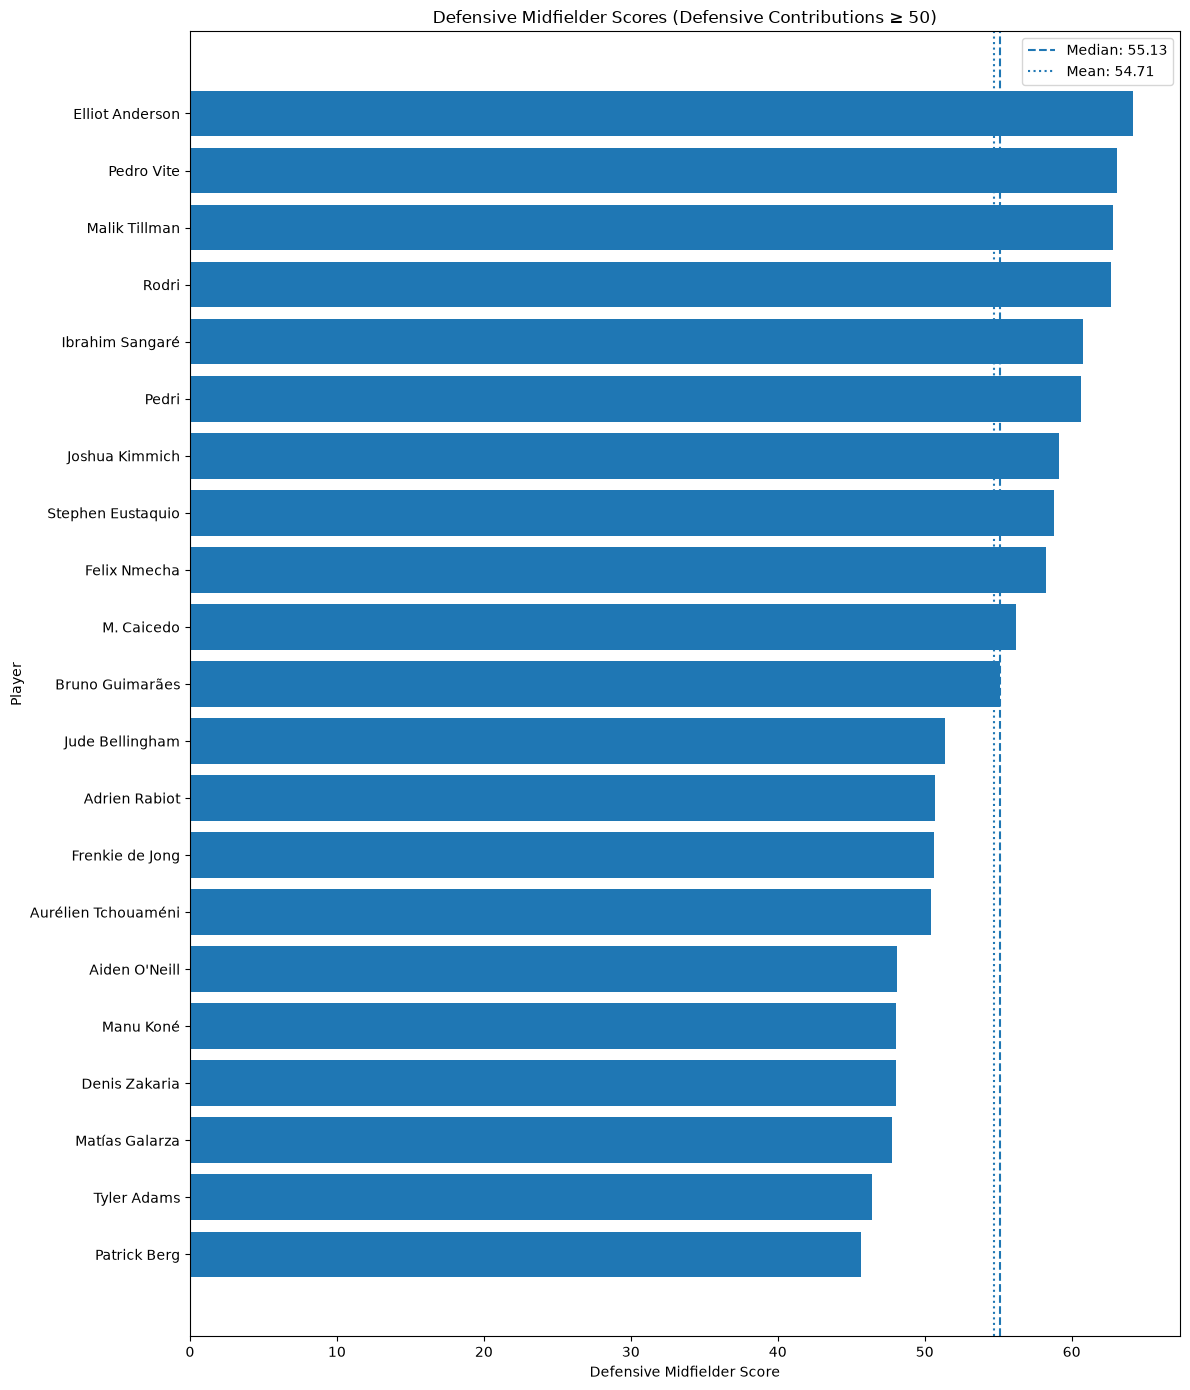

Eligible players displayed: 21
Defensive contribution threshold: 50


In [83]:
import matplotlib.pyplot as plt

# Filter players for the graph only
defensive_threshold = 50

dm_plot = score_df[
    score_df["Defensive Contributions_Score"] >= defensive_threshold
].sort_values(
    "Defensive_Midfielder_Score",
    ascending=True
).copy()

# Calculate median and mean from eligible players
median_score = dm_plot["Defensive_Midfielder_Score"].median()
mean_score = dm_plot["Defensive_Midfielder_Score"].mean()

# Create chart
plt.figure(figsize=(12, 14))

plt.barh(
    dm_plot["Player"],
    dm_plot["Defensive_Midfielder_Score"]
)

# Reference lines
plt.axvline(
    median_score,
    linestyle="--",
    label=f"Median: {median_score:.2f}"
)

plt.axvline(
    mean_score,
    linestyle=":",
    label=f"Mean: {mean_score:.2f}"
)

plt.xlabel("Defensive Midfielder Score")
plt.ylabel("Player")
plt.title(
    f"Defensive Midfielder Scores "
    f"(Defensive Contributions ≥ {defensive_threshold})"
)
plt.legend()
plt.tight_layout()
plt.show()

print("Eligible players displayed:", len(dm_plot))
print("Defensive contribution threshold:", defensive_threshold)

In [84]:
# Calculate median using defensively eligible players only
defensive_threshold = 50

dm_eligible = score_df[
    score_df["Defensive Contributions_Score"] >= defensive_threshold
].copy()

dm_median = dm_eligible["Defensive_Midfielder_Score"].median()

# Select eligible players above the median
dm_candidates = dm_eligible[
    dm_eligible["Defensive_Midfielder_Score"] > dm_median
].sort_values(
    "Defensive_Midfielder_Score",
    ascending=False
).copy()

print("Defensive contribution threshold:", defensive_threshold)
print("Median DM score among eligible players:", round(dm_median, 2))
print("Eligible players:", len(dm_eligible))
print("Candidates above median:", len(dm_candidates))

dm_candidates[
    [
        "Player",
        "Minutes",
        "Defensive Contributions_Score",
        "Defensive_Midfielder_Score"
    ]
]

Defensive contribution threshold: 50
Median DM score among eligible players: 55.13
Eligible players: 21
Candidates above median: 10


,Player,Minutes,Defensive Contributions_Score,Defensive_Midfielder_Score
25,Elliot Anderson,718,82.682927,64.162788
31,Pedro Vite,410,68.963415,63.104885
11,Malik Tillman,417,69.390244,62.800929
5,Rodri,825,72.073171,62.667159
48,Ibrahim Sangaré,307,84.634146,60.786062
29,Pedri,571,54.512195,60.652559
22,Joshua Kimmich,411,53.658537,59.165896
26,Stephen Eustaquio,446,58.902439,58.830113
44,Felix Nmecha,303,72.317073,58.256278
28,M. Caicedo,410,63.414634,56.203509


In [85]:
dm_candidates[
    [
        "Player",
        "Minutes",
        "Goal Threat & Finishing_Score",
        "Attacking Positioning_Score",
        "Creativity_Score",
        "Passing & Progression_Score",
        "Ball Carrying & Dribbling_Score",
        "Defensive Contributions_Score",
        "Discipline_Score",
        "Defensive_Midfielder_Score"
    ]
]

,Player,Minutes,Goal Threat & Finishing_Score,Attacking Positioning_Score,Creativity_Score,Passing & Progression_Score,Ball Carrying & Dribbling_Score,Defensive Contributions_Score,Discipline_Score,Defensive_Midfielder_Score
25,Elliot Anderson,718,45.564415,27.195122,42.804878,64.817073,57.416560,82.682927,45.365854,64.162788
31,Pedro Vite,410,40.287680,27.560976,77.195122,75.670732,34.350128,68.963415,60.243902,63.104885
11,Malik Tillman,417,86.156973,79.390244,48.536585,43.719512,74.484917,69.390244,47.317073,62.800929
5,Rodri,825,37.196685,57.195122,56.829268,78.597561,41.830873,72.073171,49.268293,62.667159
48,Ibrahim Sangaré,307,19.940588,41.829268,43.292683,55.548780,55.611361,84.634146,58.048780,60.786062
29,Pedri,571,50.320513,63.048780,76.097561,74.329268,43.754814,54.512195,50.243902,60.652559
22,Joshua Kimmich,411,41.830832,16.951220,83.292683,71.646341,48.636072,53.658537,63.414634,59.165896
26,Stephen Eustaquio,446,42.909631,26.707317,67.560976,71.646341,27.642811,58.902439,61.463415,58.830113
44,Felix Nmecha,303,73.857098,82.195122,45.609756,37.621951,68.904044,72.317073,53.170732,58.256278
28,M. Caicedo,410,42.726704,35.853659,57.012195,65.548780,20.888960,63.414634,37.317073,56.203509


Your model allows different types of players to score well for different reasons:
- Malik Tillman: strong defensive contributions and ball carrying, despite weaker passing.
- Pedri: strong passing, progression and creativity, despite a lower defensive contribution score.
- Rodri: a combination of passing/progression and defensive contributions.
- Elliot Anderson: a high overall score supported by strong defensive contributions.
Those differences are useful. Your model is identifying players who could contribute in the defensive-midfield position in different ways, rather than insisting they all have the same strengths.

Now we're moving to the market-value and cost-efficiency stage of your project.

In [86]:
#Market Values based on 29-10-2026

In [87]:
market_values = {
    "Elliot Anderson": 75,
    "Pedro Vite": 6,
    "Malik Tillman": 30,
    "Rodri": 50,
    "Ibrahim Sangaré": 20,
    "Pedri": 150,
    "Joshua Kimmich": 35,
    "Stephen Eustaquio": 6,
    "Felix Nmecha": 50,
    "M. Caicedo": 100
}

dm_value_df = dm_candidates[
    ["Player", "Minutes", "Defensive_Midfielder_Score"]
].copy()

dm_value_df["Market_Value_EUR_m"] = (
    dm_value_df["Player"].map(market_values)
)

dm_value_df["Points_per_EUR_m"] = (
    dm_value_df["Defensive_Midfielder_Score"]
    / dm_value_df["Market_Value_EUR_m"]
)

dm_value_df = dm_value_df.sort_values(
    "Points_per_EUR_m",
    ascending=False
)

dm_value_df

,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m
31,Pedro Vite,410,63.104885,6,10.517481
26,Stephen Eustaquio,446,58.830113,6,9.805019
48,Ibrahim Sangaré,307,60.786062,20,3.039303
11,Malik Tillman,417,62.800929,30,2.093364
22,Joshua Kimmich,411,59.165896,35,1.690454
5,Rodri,825,62.667159,50,1.253343
44,Felix Nmecha,303,58.256278,50,1.165126
25,Elliot Anderson,718,64.162788,75,0.855504
28,M. Caicedo,410,56.203509,100,0.562035
29,Pedri,571,60.652559,150,0.404350


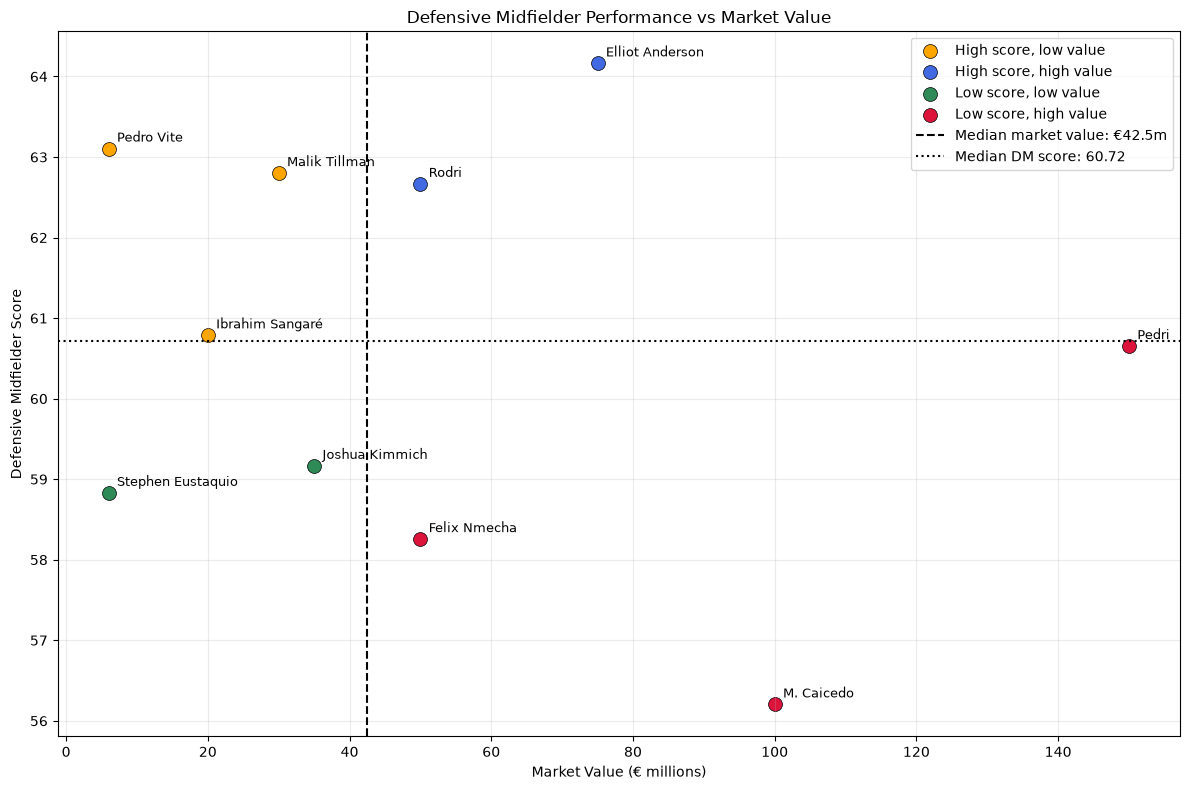

Median market value (€m): 42.5
Median DM score: 60.72


In [88]:

import matplotlib.pyplot as plt

# Keep only players with both values available
plot_df = dm_value_df.dropna(
    subset=["Market_Value_EUR_m", "Defensive_Midfielder_Score"]
).copy()

# Calculate median lines
median_value = plot_df["Market_Value_EUR_m"].median()
median_score = plot_df["Defensive_Midfielder_Score"].median()

# Classify players into quadrants
def assign_quadrant(row):
    if (
        row["Market_Value_EUR_m"] < median_value
        and row["Defensive_Midfielder_Score"] >= median_score
    ):
        return "High score, low value"

    elif (
        row["Market_Value_EUR_m"] >= median_value
        and row["Defensive_Midfielder_Score"] >= median_score
    ):
        return "High score, high value"

    elif (
        row["Market_Value_EUR_m"] < median_value
        and row["Defensive_Midfielder_Score"] < median_score
    ):
        return "Low score, low value"

    else:
        return "Low score, high value"


plot_df["Quadrant"] = plot_df.apply(assign_quadrant, axis=1)

# Different colour for each quadrant
quadrant_colours = {
    "High score, low value": "orange",
    "High score, high value": "royalblue",
    "Low score, low value": "seagreen",
    "Low score, high value": "crimson"
}

plt.figure(figsize=(12, 8))

# Plot each quadrant separately
for quadrant, colour in quadrant_colours.items():
    group = plot_df[plot_df["Quadrant"] == quadrant]

    plt.scatter(
        group["Market_Value_EUR_m"],
        group["Defensive_Midfielder_Score"],
        color=colour,
        s=100,
        label=quadrant,
        edgecolor="black",
        linewidth=0.5
    )

# Label each player
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Player"],
        (
            row["Market_Value_EUR_m"],
            row["Defensive_Midfielder_Score"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

# Median lines
plt.axvline(
    median_value,
    color="black",
    linestyle="--",
    label=f"Median market value: €{median_value:.1f}m"
)

plt.axhline(
    median_score,
    color="black",
    linestyle=":",
    label=f"Median DM score: {median_score:.2f}"
)

plt.xlabel("Market Value (€ millions)")
plt.ylabel("Defensive Midfielder Score")
plt.title("Defensive Midfielder Performance vs Market Value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Median market value (€m):", round(median_value, 2))
print("Median DM score:", round(median_score, 2))


In [89]:
dm_value_df

,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m
31,Pedro Vite,410,63.104885,6,10.517481
26,Stephen Eustaquio,446,58.830113,6,9.805019
48,Ibrahim Sangaré,307,60.786062,20,3.039303
11,Malik Tillman,417,62.800929,30,2.093364
22,Joshua Kimmich,411,59.165896,35,1.690454
5,Rodri,825,62.667159,50,1.253343
44,Felix Nmecha,303,58.256278,50,1.165126
25,Elliot Anderson,718,64.162788,75,0.855504
28,M. Caicedo,410,56.203509,100,0.562035
29,Pedri,571,60.652559,150,0.404350


In [90]:
# Median efficiency of the 10 shortlisted players
median_efficiency = dm_value_df["Points_per_EUR_m"].median()

# Compare each player's efficiency with the median
dm_value_df["Relative_Cost_Efficiency_%"] = (
    (dm_value_df["Points_per_EUR_m"] / median_efficiency) - 1
) * 100

dm_value_df = dm_value_df.sort_values(
    "Relative_Cost_Efficiency_%",
    ascending=False
)

dm_value_df[
    [
        "Player",
        "Minutes",
        "Defensive_Midfielder_Score",
        "Market_Value_EUR_m",
        "Points_per_EUR_m",
        "Relative_Cost_Efficiency_%"
    ]
].round(2)

,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%
31,Pedro Vite,410,63.10,6,10.52,614.55
26,Stephen Eustaquio,446,58.83,6,9.81,566.15
48,Ibrahim Sangaré,307,60.79,20,3.04,106.49
11,Malik Tillman,417,62.80,30,2.09,42.22
22,Joshua Kimmich,411,59.17,35,1.69,14.85
5,Rodri,825,62.67,50,1.25,-14.85
44,Felix Nmecha,303,58.26,50,1.17,-20.84
25,Elliot Anderson,718,64.16,75,0.86,-41.88
28,M. Caicedo,410,56.20,100,0.56,-61.82
29,Pedri,571,60.65,150,0.40,-72.53


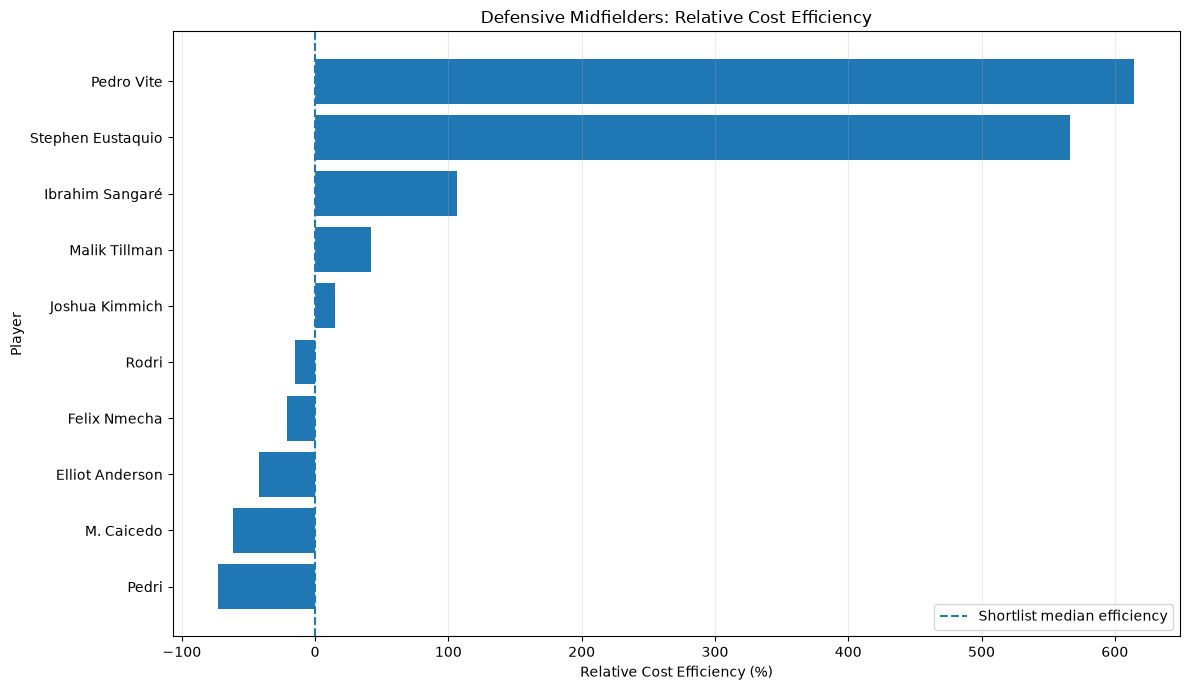

In [91]:

import matplotlib.pyplot as plt

# Sort players from lowest to highest efficiency
plot_df = dm_value_df.sort_values(
    "Relative_Cost_Efficiency_%",
    ascending=True
).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    plot_df["Player"],
    plot_df["Relative_Cost_Efficiency_%"]
)

# Zero line = median efficiency of your shortlist
plt.axvline(
    0,
    linestyle="--",
    label="Shortlist median efficiency"
)

plt.xlabel("Relative Cost Efficiency (%)")
plt.ylabel("Player")
plt.title(
    "Defensive Midfielders: Relative Cost Efficiency"
)

plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


In [92]:

DMF_Recruitment_table = dm_value_df.copy()


# Keep the columns needed for recruitment comparison
DMF_Recruitment_table = DMF_Recruitment_table[
    [
        "Player",
        "Minutes",
        "Defensive_Midfielder_Score",
        "Market_Value_EUR_m",
        "Points_per_EUR_m",
        "Relative_Cost_Efficiency_%",
    ]
].round(2)

DMF_Recruitment_table


,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%
31,Pedro Vite,410,63.10,6,10.52,614.55
26,Stephen Eustaquio,446,58.83,6,9.81,566.15
48,Ibrahim Sangaré,307,60.79,20,3.04,106.49
11,Malik Tillman,417,62.80,30,2.09,42.22
22,Joshua Kimmich,411,59.17,35,1.69,14.85
5,Rodri,825,62.67,50,1.25,-14.85
44,Felix Nmecha,303,58.26,50,1.17,-20.84
25,Elliot Anderson,718,64.16,75,0.86,-41.88
28,M. Caicedo,410,56.20,100,0.56,-61.82
29,Pedri,571,60.65,150,0.40,-72.53


In [93]:

# Calculate the median benchmarks
performance_median = DMF_Recruitment_table[
    "Defensive_Midfielder_Score"
].median()

efficiency_median = DMF_Recruitment_table[
    "Points_per_EUR_m"
].median()

# Assign categories based on both metrics
def classify_player(row):
    high_performance = (
        row["Defensive_Midfielder_Score"] >= performance_median
    )

    high_efficiency = (
        row["Points_per_EUR_m"] >= efficiency_median
    )

    if high_performance and high_efficiency:
        return "High Performance, High Cost Efficiency"

    elif high_performance and not high_efficiency:
        return "High Performance, Low Cost Efficiency"

    elif not high_performance and high_efficiency:
        return "Low Performance, High Cost Efficiency"

    else:
        return "Low Performance, Low Cost Efficiency"


DMF_Recruitment_table["Recruitment_Category"] = DMF_Recruitment_table.apply(
    classify_player,
    axis=1
)

DMF_Recruitment_table = DMF_Recruitment_table.sort_values(
    ["Recruitment_Category", "Defensive_Midfielder_Score"],
    ascending=[True, False]
)
# Display the results
DMF_Recruitment_table[
    [
        "Player",
        "Minutes",
        "Defensive_Midfielder_Score",
        "Market_Value_EUR_m",
        "Points_per_EUR_m",
        "Recruitment_Category"
    ]
].sort_values(
    ["Recruitment_Category", "Defensive_Midfielder_Score"],
    ascending=[True, False]
)



,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Recruitment_Category
31,Pedro Vite,410,63.10,6,10.52,"High Performance, High Cost Efficiency"
11,Malik Tillman,417,62.80,30,2.09,"High Performance, High Cost Efficiency"
48,Ibrahim Sangaré,307,60.79,20,3.04,"High Performance, High Cost Efficiency"
25,Elliot Anderson,718,64.16,75,0.86,"High Performance, Low Cost Efficiency"
5,Rodri,825,62.67,50,1.25,"High Performance, Low Cost Efficiency"
22,Joshua Kimmich,411,59.17,35,1.69,"Low Performance, High Cost Efficiency"
26,Stephen Eustaquio,446,58.83,6,9.81,"Low Performance, High Cost Efficiency"
29,Pedri,571,60.65,150,0.40,"Low Performance, Low Cost Efficiency"
44,Felix Nmecha,303,58.26,50,1.17,"Low Performance, Low Cost Efficiency"
28,M. Caicedo,410,56.20,100,0.56,"Low Performance, Low Cost Efficiency"


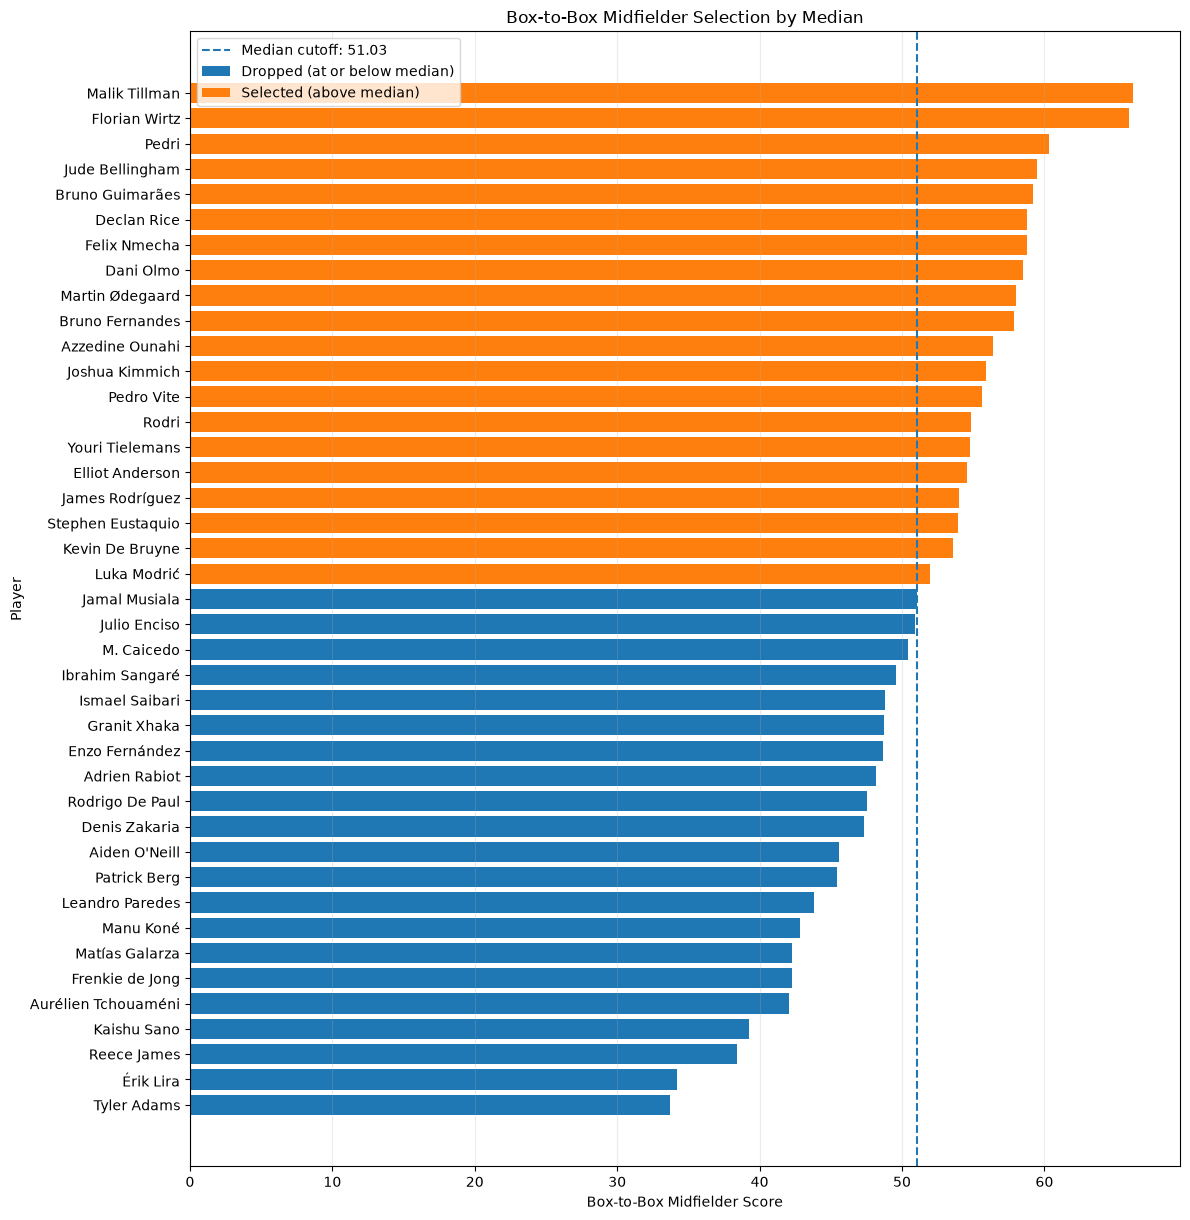

In [94]:

import matplotlib.pyplot as plt

b2b_median = score_df["Box_to_Box_Midfielder_Score"].median()
# Copy all players with their Box-to-Box scores
b2b_plot_df = score_df[
    ["Player", "Box_to_Box_Midfielder_Score"]
].dropna().copy()

# Identify retained and dropped players
b2b_plot_df["Selection"] = b2b_plot_df[
    "Box_to_Box_Midfielder_Score"
].apply(
    lambda score: "Selected" if score > b2b_median else "Dropped"
)

# Sort scores from lowest to highest
b2b_plot_df = b2b_plot_df.sort_values(
    "Box_to_Box_Midfielder_Score",
    ascending=True
)

# Separate players into two groups for plotting
selected = b2b_plot_df["Selection"] == "Selected"
dropped = ~selected

plt.figure(figsize=(12, max(7, len(b2b_plot_df) * 0.3)))

# Plot all players, distinguishing selected vs dropped
plt.barh(
    b2b_plot_df.loc[dropped, "Player"],
    b2b_plot_df.loc[dropped, "Box_to_Box_Midfielder_Score"],
    label="Dropped (at or below median)"
)

plt.barh(
    b2b_plot_df.loc[selected, "Player"],
    b2b_plot_df.loc[selected, "Box_to_Box_Midfielder_Score"],
    label="Selected (above median)"
)

# Median cutoff
plt.axvline(
    b2b_median,
    linestyle="--",
    label=f"Median cutoff: {b2b_median:.2f}"
)

plt.xlabel("Box-to-Box Midfielder Score")
plt.ylabel("Player")
plt.title("Box-to-Box Midfielder Selection by Median")
plt.legend()
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


In [95]:

# Calculate the median Box-to-Box score
b2b_median = score_df["Box_to_Box_Midfielder_Score"].median()

print("Box-to-Box Median Score:", round(b2b_median, 2))

# Select players scoring ABOVE the median
b2b_candidates = score_df[
    score_df["Box_to_Box_Midfielder_Score"] > b2b_median
].copy()

# Sort candidates from highest score to lowest
b2b_candidates = b2b_candidates.sort_values(
    "Box_to_Box_Midfielder_Score",
    ascending=False
)

# Display the selected players
b2b_candidates[
    ["Player", "Minutes", "Box_to_Box_Midfielder_Score"]
]


Box-to-Box Median Score: 51.03


,Player,Minutes,Box_to_Box_Midfielder_Score
11,Malik Tillman,417,66.209699
33,Florian Wirtz,409,65.937940
29,Pedri,571,60.330992
27,Jude Bellingham,704,59.495037
37,Bruno Guimarães,462,59.202149
40,Declan Rice,626,58.784254
44,Felix Nmecha,303,58.780777
45,Dani Olmo,541,58.518910
17,Martin Ødegaard,541,57.992184
1,Bruno Fernandes,475,57.897321


In [96]:

market_values_b2b = {
    "Malik Tillman": 30.0,
    "Florian Wirtz": 125.0,
    "Pedri": 150.0,
    "Jude Bellingham": 170.0,
    "Bruno Guimarães": 75.0,
    "Declan Rice": 120.0,
    "Felix Nmecha": 55.0,
    "Dani Olmo": 60.0,
    "Martin Ødegaard": 65.0,
    "Bruno Fernandes": 70.0,
    "Azzedine Ounahi": 16.0,
    "Joshua Kimmich": 35.0,
    "Pedro Vite": 6.0,
    "Rodri": 50.0,
    "Youri Tielemans": 30.0,
    "Elliot Anderson": 120.0,
    "James Rodríguez": 1.5,
    "Stephen Eustaquio": 6.0,
    "Kevin De Bruyne": 8.0,
    "Luka Modrić": 3.5
}

# Add market values to your existing shortlist
b2b_value_df = b2b_candidates[
    ["Player", "Minutes", "Box_to_Box_Midfielder_Score"]
].copy()

b2b_value_df["Market_Value_EUR_m"] = (
    b2b_value_df["Player"].map(market_values_b2b)
)

b2b_value_df


,Player,Minutes,Box_to_Box_Midfielder_Score,Market_Value_EUR_m
11,Malik Tillman,417,66.209699,30.0
33,Florian Wirtz,409,65.937940,125.0
29,Pedri,571,60.330992,150.0
27,Jude Bellingham,704,59.495037,170.0
37,Bruno Guimarães,462,59.202149,75.0
40,Declan Rice,626,58.784254,120.0
44,Felix Nmecha,303,58.780777,55.0
45,Dani Olmo,541,58.518910,60.0
17,Martin Ødegaard,541,57.992184,65.0
1,Bruno Fernandes,475,57.897321,70.0


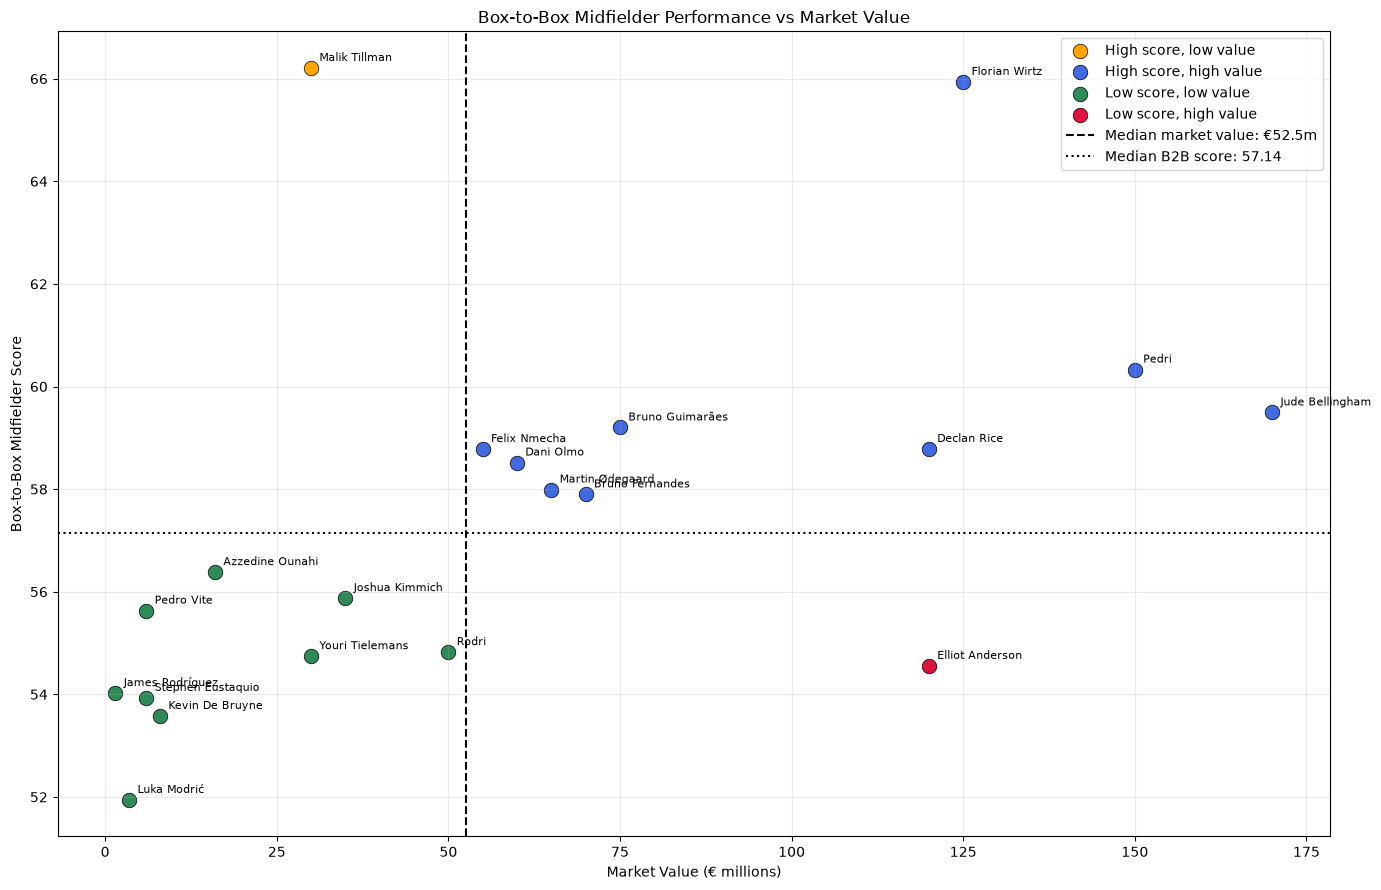

Median market value (€m): 52.5
Median Box-to-Box score: 57.14


In [97]:

import matplotlib.pyplot as plt

# Keep rows with both values available
plot_df = b2b_value_df.dropna(
    subset=[
        "Market_Value_EUR_m",
        "Box_to_Box_Midfielder_Score"
    ]
).copy()

# Calculate the two medians
median_value = plot_df["Market_Value_EUR_m"].median()
median_score = plot_df["Box_to_Box_Midfielder_Score"].median()

# Classify each player by quadrant
def assign_quadrant(row):
    if (
        row["Market_Value_EUR_m"] < median_value
        and row["Box_to_Box_Midfielder_Score"] >= median_score
    ):
        return "High score, low value"

    elif (
        row["Market_Value_EUR_m"] >= median_value
        and row["Box_to_Box_Midfielder_Score"] >= median_score
    ):
        return "High score, high value"

    elif (
        row["Market_Value_EUR_m"] < median_value
        and row["Box_to_Box_Midfielder_Score"] < median_score
    ):
        return "Low score, low value"

    else:
        return "Low score, high value"


plot_df["Quadrant"] = plot_df.apply(assign_quadrant, axis=1)

# Give each quadrant its own colour
quadrant_colours = {
    "High score, low value": "orange",
    "High score, high value": "royalblue",
    "Low score, low value": "seagreen",
    "Low score, high value": "crimson"
}

plt.figure(figsize=(14, 9))

# Plot each quadrant as a separate group
for quadrant, colour in quadrant_colours.items():
    group = plot_df[plot_df["Quadrant"] == quadrant]

    plt.scatter(
        group["Market_Value_EUR_m"],
        group["Box_to_Box_Midfielder_Score"],
        color=colour,
        s=110,
        label=quadrant,
        edgecolor="black",
        linewidth=0.5
    )

# Label each player
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Player"],
        (
            row["Market_Value_EUR_m"],
            row["Box_to_Box_Midfielder_Score"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8
    )

# Median lines
plt.axvline(
    median_value,
    color="black",
    linestyle="--",
    label=f"Median market value: €{median_value:.1f}m"
)

plt.axhline(
    median_score,
    color="black",
    linestyle=":",
    label=f"Median B2B score: {median_score:.2f}"
)

plt.xlabel("Market Value (€ millions)")
plt.ylabel("Box-to-Box Midfielder Score")
plt.title("Box-to-Box Midfielder Performance vs Market Value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Median market value (€m):", round(median_value, 2))
print("Median Box-to-Box score:", round(median_score, 2))


In [98]:

# Calculate points per €1 million
b2b_value_df["Points_per_EUR_m"] = (
    b2b_value_df["Box_to_Box_Midfielder_Score"]
    / b2b_value_df["Market_Value_EUR_m"]
)

# Find the median points
median_points = b2b_value_df["Points_per_EUR_m"].median()

# Calculate relative efficiency compared with the median
b2b_value_df["Relative_Cost_Efficiency_%"] = (
    (b2b_value_df["Points_per_EUR_m"] - median_points)
    / median_points
) * 100

# Display the table, highest points first
b2b_value_df = b2b_value_df.sort_values(
    by="Points_per_EUR_m",
    ascending=False
).reset_index(drop=True)

b2b_value_df.round({
    "Box_to_Box_Midfielder_Score": 2,
    "Market_Value_EUR_m": 2,
    "Points_per_EUR_m": 3,
    "Relative_Cost_Efficiency_%": 2
})


,Player,Minutes,Box_to_Box_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%
0,James Rodríguez,344,54.02,1.5,36.016,3226.84
1,Luka Modrić,363,51.94,3.5,14.841,1270.84
2,Pedro Vite,410,55.63,6.0,9.272,756.46
3,Stephen Eustaquio,446,53.93,6.0,8.989,730.27
4,Kevin De Bruyne,416,53.58,8.0,6.697,518.64
5,Azzedine Ounahi,482,56.38,16.0,3.524,225.50
6,Malik Tillman,417,66.21,30.0,2.207,103.86
7,Youri Tielemans,541,54.74,30.0,1.825,68.56
8,Joshua Kimmich,411,55.88,35.0,1.596,47.47
9,Rodri,825,54.82,50.0,1.096,1.28


In [99]:

# Calculate the median performance score
b2b_score_median = b2b_value_df[
    "Box_to_Box_Midfielder_Score"
].median()

# Calculate the median cost-efficiency points
b2b_points_median = b2b_value_df["Points_per_EUR_m"].median()

# Classify each player into one of four categories
def classify_b2b_player(row):

    high_performance = (
        row["Box_to_Box_Midfielder_Score"] >= b2b_score_median
    )

    high_cost_efficiency = (
        row["Points_per_EUR_m"] >= b2b_points_median
    )

    if high_performance and high_cost_efficiency:
        return "High Performance, High Cost Efficiency"

    elif high_performance and not high_cost_efficiency:
        return "High Performance, Low Cost Efficiency"

    elif not high_performance and high_cost_efficiency:
        return "Low Performance, High Cost Efficiency"

    else:
        return "Low Performance, Low Cost Efficiency"


# Create a new classification column
b2b_value_df["Recruitment_Category"] = b2b_value_df.apply(
    classify_b2b_player,
    axis=1
)

# Create the recruitment category table
Box2Box_Recruitment_table = b2b_value_df[
    [
        "Player",
        "Minutes",
        "Box_to_Box_Midfielder_Score",
        "Market_Value_EUR_m",
        "Points_per_EUR_m",
        "Relative_Cost_Efficiency_%",
        "Recruitment_Category"
    ]
].sort_values(
    by=["Recruitment_Category", "Points_per_EUR_m"],
    ascending=[True, False]
).reset_index(drop=True)

Box2Box_Recruitment_table.round({
    "Box_to_Box_Midfielder_Score": 2,
    "Market_Value_EUR_m": 2,
    "Points_per_EUR_m": 3,
    "Relative_Cost_Efficiency_%": 2
})


,Player,Minutes,Box_to_Box_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%,Recruitment_Category
0,Malik Tillman,417,66.21,30.0,2.207,103.86,"High Performance, High Cost Efficiency"
1,Felix Nmecha,303,58.78,55.0,1.069,-1.28,"High Performance, Low Cost Efficiency"
2,Dani Olmo,541,58.52,60.0,0.975,-9.91,"High Performance, Low Cost Efficiency"
3,Martin Ødegaard,541,57.99,65.0,0.892,-17.59,"High Performance, Low Cost Efficiency"
4,Bruno Fernandes,475,57.90,70.0,0.827,-23.60,"High Performance, Low Cost Efficiency"
5,Bruno Guimarães,462,59.20,75.0,0.789,-27.09,"High Performance, Low Cost Efficiency"
6,Florian Wirtz,409,65.94,125.0,0.528,-51.27,"High Performance, Low Cost Efficiency"
7,Declan Rice,626,58.78,120.0,0.490,-54.75,"High Performance, Low Cost Efficiency"
8,Pedri,571,60.33,150.0,0.402,-62.85,"High Performance, Low Cost Efficiency"
9,Jude Bellingham,704,59.50,170.0,0.350,-67.67,"High Performance, Low Cost Efficiency"


In [100]:
am_mean = score_df["Attacking_Midfielder_Score"].mean()

print("Mean Attacking Midfielder Score:", round(am_mean, 2))

Mean Attacking Midfielder Score: 51.02


In [101]:
am_candidates = score_df[
    score_df["Attacking_Midfielder_Score"] > am_mean
].copy()

am_candidates = am_candidates.sort_values(
    by="Attacking_Midfielder_Score",
    ascending=False
).reset_index(drop=True)

print("Number of AM candidates:", len(am_candidates))

am_candidates[
    ["Player", "Minutes", "Attacking_Midfielder_Score"]
]

Number of AM candidates: 21


,Player,Minutes,Attacking_Midfielder_Score
0,Florian Wirtz,409,73.255082
1,Malik Tillman,417,68.794257
2,Dani Olmo,541,65.348172
3,Jude Bellingham,704,65.140599
4,Declan Rice,626,63.851622
5,Bruno Guimarães,462,63.468812
6,Martin Ødegaard,541,62.372093
7,Kevin De Bruyne,416,62.354390
8,James Rodríguez,344,61.953355
9,Pedri,571,61.639790


In [102]:

# Market values in millions of euros
market_values_am = {
    "Florian Wirtz": 125.0,
    "Malik Tillman": 30.0,
    "Dani Olmo": 60.0,
    "Jude Bellingham": 170.0,
    "Declan Rice": 120.0,
    "Bruno Guimarães": 75.0,
    "Martin Ødegaard": 65.0,
    "Kevin De Bruyne": 8.0,
    "James Rodríguez": 1.5,
    "Pedri": 150.0,
    "Azzedine Ounahi": 16.0,
    "Youri Tielemans": 30.0,
    "Bruno Fernandes": 70.0,
    "Felix Nmecha": 55.0,
    "Julio Enciso": 25.0,
    "Jamal Musiala": 80.0,
    "Ismael Saibari": 40.0,
    "Joshua Kimmich": 35.0,
    "Stephen Eustaquio": 6.0,
    "Pedro Vite": 6.0,
    "Luka Modrić": 3.5
}

# Create a separate AM valuation table
am_value_df = am_candidates[
    ["Player", "Minutes", "Attacking_Midfielder_Score"]
].copy()

# Match each player with their market value
am_value_df["Market_Value_EUR_m"] = (
    am_value_df["Player"].map(market_values_am)
)

# Check the result
am_value_df


,Player,Minutes,Attacking_Midfielder_Score,Market_Value_EUR_m
0,Florian Wirtz,409,73.255082,125.0
1,Malik Tillman,417,68.794257,30.0
2,Dani Olmo,541,65.348172,60.0
3,Jude Bellingham,704,65.140599,170.0
4,Declan Rice,626,63.851622,120.0
5,Bruno Guimarães,462,63.468812,75.0
6,Martin Ødegaard,541,62.372093,65.0
7,Kevin De Bruyne,416,62.354390,8.0
8,James Rodríguez,344,61.953355,1.5
9,Pedri,571,61.639790,150.0


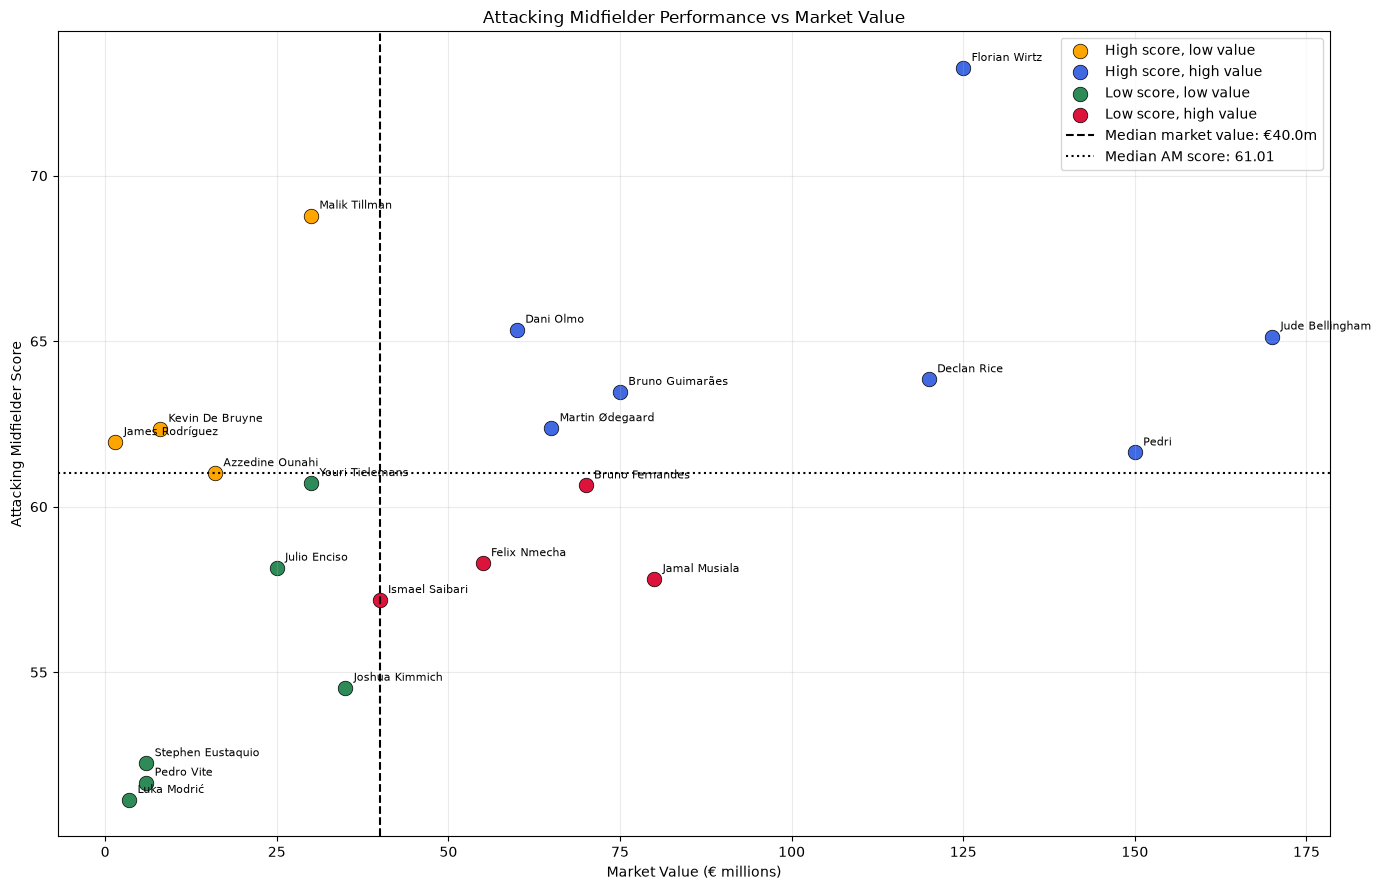

Median market value (€m): 40.0
Median Attacking Midfielder score: 61.01


In [103]:
import matplotlib.pyplot as plt

# Keep rows with both values available
plot_df = am_value_df.dropna(
    subset=[
        "Market_Value_EUR_m",
        "Attacking_Midfielder_Score"
    ]
).copy()

# Calculate the two medians
median_value = plot_df["Market_Value_EUR_m"].median()
median_score = plot_df["Attacking_Midfielder_Score"].median()

# Classify each player by quadrant
def assign_quadrant(row):
    if (
        row["Market_Value_EUR_m"] < median_value
        and row["Attacking_Midfielder_Score"] >= median_score
    ):
        return "High score, low value"

    elif (
        row["Market_Value_EUR_m"] >= median_value
        and row["Attacking_Midfielder_Score"] >= median_score
    ):
        return "High score, high value"

    elif (
        row["Market_Value_EUR_m"] < median_value
        and row["Attacking_Midfielder_Score"] < median_score
    ):
        return "Low score, low value"

    else:
        return "Low score, high value"


plot_df["Quadrant"] = plot_df.apply(assign_quadrant, axis=1)

# Give each quadrant its own colour
quadrant_colours = {
    "High score, low value": "orange",
    "High score, high value": "royalblue",
    "Low score, low value": "seagreen",
    "Low score, high value": "crimson"
}

plt.figure(figsize=(14, 9))

# Plot each quadrant as a separate group
for quadrant, colour in quadrant_colours.items():
    group = plot_df[plot_df["Quadrant"] == quadrant]

    plt.scatter(
        group["Market_Value_EUR_m"],
        group["Attacking_Midfielder_Score"],
        color=colour,
        s=110,
        label=quadrant,
        edgecolor="black",
        linewidth=0.5
    )

# Label each player
for _, row in plot_df.iterrows():
    plt.annotate(
        row["Player"],
        (
            row["Market_Value_EUR_m"],
            row["Attacking_Midfielder_Score"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8
    )

# Median lines
plt.axvline(
    median_value,
    color="black",
    linestyle="--",
    label=f"Median market value: €{median_value:.1f}m"
)

plt.axhline(
    median_score,
    color="black",
    linestyle=":",
    label=f"Median AM score: {median_score:.2f}"
)

plt.xlabel("Market Value (€ millions)")
plt.ylabel("Attacking Midfielder Score")
plt.title("Attacking Midfielder Performance vs Market Value")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Median market value (€m):", round(median_value, 2))
print("Median Attacking Midfielder score:", round(median_score, 2))

In [104]:

# Step 1: Calculate points per €1 million
am_value_df["Points_per_EUR_m"] = (
    am_value_df["Attacking_Midfielder_Score"]
    / am_value_df["Market_Value_EUR_m"]
)

# Step 2: Calculate median points
am_median_points = am_value_df["Points_per_EUR_m"].median()

# Step 3: Calculate relative cost efficiency
am_value_df["Relative_Cost_Efficiency_%"] = (
    (am_value_df["Points_per_EUR_m"] - am_median_points)
    / am_median_points
) * 100

# Step 4: Sort players by Points_per_EUR_m, highest first
am_value_df = am_value_df.sort_values(
    by="Points_per_EUR_m",
    ascending=False
).reset_index(drop=True)

# Step 5: Display the completed table
am_value_df.round({
    "Attacking_Midfielder_Score": 2,
    "Market_Value_EUR_m": 2,
    "Points_per_EUR_m": 3,
    "Relative_Cost_Efficiency_%": 2
})


,Player,Minutes,Attacking_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%
0,James Rodríguez,344,61.95,1.5,41.302,2789.16
1,Luka Modrić,363,51.14,3.5,14.612,922.16
2,Stephen Eustaquio,446,52.25,6.0,8.709,509.19
3,Pedro Vite,410,51.66,6.0,8.611,502.34
4,Kevin De Bruyne,416,62.35,8.0,7.794,445.22
5,Azzedine Ounahi,482,61.01,16.0,3.813,166.75
6,Julio Enciso,435,58.16,25.0,2.326,62.73
7,Malik Tillman,417,68.79,30.0,2.293,60.41
8,Youri Tielemans,541,60.71,30.0,2.024,41.57
9,Joshua Kimmich,411,54.53,35.0,1.558,8.99


In [105]:
print("Median AM points:", round(am_median_points, 3))

Median AM points: 1.43


In [106]:
# Calculate the median values
am_median_score = am_value_df["Attacking_Midfielder_Score"].median()
am_median_points = am_value_df["Points_per_EUR_m"].median()

# Classify each attacking midfielder
def classify_am_player(row):
    if (
        row["Attacking_Midfielder_Score"] >= am_median_score
        and row["Points_per_EUR_m"] >= am_median_points
    ):
        return "High Performance, High Cost Efficiency"

    elif (
        row["Attacking_Midfielder_Score"] >= am_median_score
        and row["Points_per_EUR_m"] < am_median_points
    ):
        return "High Performance, Low Cost Efficiency"

    elif (
        row["Attacking_Midfielder_Score"] < am_median_score
        and row["Points_per_EUR_m"] >= am_median_points
    ):
        return "Low Performance, High Cost Efficiency"

    else:
        return "Low Performance, Low Cost Efficiency"


# Create the category column
am_value_df["Recruitment_Category"] = am_value_df.apply(
    classify_am_player,
    axis=1
)

# Create the final table
AMF_Recruitment_table = am_value_df[
    [
        "Player",
        "Minutes",
        "Attacking_Midfielder_Score",
        "Market_Value_EUR_m",
        "Points_per_EUR_m",
        "Relative_Cost_Efficiency_%",
        "Recruitment_Category"
    ]
].sort_values(
    by=["Recruitment_Category", "Attacking_Midfielder_Score"],
    ascending=[True, False]
).reset_index(drop=True)

# Display the table

AMF_Recruitment_table.round({
    "Attacking_Midfielder_Score": 2,
    "Market_Value_EUR_m": 2,
    "Points_per_EUR_m": 3,
    "Relative_Cost_Efficiency_%": 2
})

,Player,Minutes,Attacking_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%,Recruitment_Category
0,Malik Tillman,417,68.79,30.0,2.293,60.41,"High Performance, High Cost Efficiency"
1,Kevin De Bruyne,416,62.35,8.0,7.794,445.22,"High Performance, High Cost Efficiency"
2,James Rodríguez,344,61.95,1.5,41.302,2789.16,"High Performance, High Cost Efficiency"
3,Azzedine Ounahi,482,61.01,16.0,3.813,166.75,"High Performance, High Cost Efficiency"
4,Florian Wirtz,409,73.26,125.0,0.586,-59.01,"High Performance, Low Cost Efficiency"
5,Dani Olmo,541,65.35,60.0,1.089,-23.81,"High Performance, Low Cost Efficiency"
6,Jude Bellingham,704,65.14,170.0,0.383,-73.20,"High Performance, Low Cost Efficiency"
7,Declan Rice,626,63.85,120.0,0.532,-62.78,"High Performance, Low Cost Efficiency"
8,Bruno Guimarães,462,63.47,75.0,0.846,-40.80,"High Performance, Low Cost Efficiency"
9,Martin Ødegaard,541,62.37,65.0,0.960,-32.88,"High Performance, Low Cost Efficiency"


In [107]:
print(DMF_Recruitment_table.columns.tolist())
print(Box2Box_Recruitment_table.columns.tolist())
print(AMF_Recruitment_table.columns.tolist())

['Player', 'Minutes', 'Defensive_Midfielder_Score', 'Market_Value_EUR_m', 'Points_per_EUR_m', 'Relative_Cost_Efficiency_%', 'Recruitment_Category']
['Player', 'Minutes', 'Box_to_Box_Midfielder_Score', 'Market_Value_EUR_m', 'Points_per_EUR_m', 'Relative_Cost_Efficiency_%', 'Recruitment_Category']
['Player', 'Minutes', 'Attacking_Midfielder_Score', 'Market_Value_EUR_m', 'Points_per_EUR_m', 'Relative_Cost_Efficiency_%', 'Recruitment_Category']


In [108]:
Box2Box_Recruitment_table


,Player,Minutes,Box_to_Box_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%,Recruitment_Category
0,Malik Tillman,417,66.209699,30.0,2.206990,103.859591,"High Performance, High Cost Efficiency"
1,Felix Nmecha,303,58.780777,55.0,1.068741,-1.280391,"High Performance, Low Cost Efficiency"
2,Dani Olmo,541,58.518910,60.0,0.975315,-9.910171,"High Performance, Low Cost Efficiency"
3,Martin Ødegaard,541,57.992184,65.0,0.892187,-17.588675,"High Performance, Low Cost Efficiency"
4,Bruno Fernandes,475,57.897321,70.0,0.827105,-23.600377,"High Performance, Low Cost Efficiency"
5,Bruno Guimarães,462,59.202149,75.0,0.789362,-27.086660,"High Performance, Low Cost Efficiency"
6,Florian Wirtz,409,65.937940,125.0,0.527504,-51.274517,"High Performance, Low Cost Efficiency"
7,Declan Rice,626,58.784254,120.0,0.489869,-54.750837,"High Performance, Low Cost Efficiency"
8,Pedri,571,60.330992,150.0,0.402207,-62.848188,"High Performance, Low Cost Efficiency"
9,Jude Bellingham,704,59.495037,170.0,0.349971,-67.673208,"High Performance, Low Cost Efficiency"


In [109]:
DMF_Recruitment_table

,Player,Minutes,Defensive_Midfielder_Score,Market_Value_EUR_m,Points_per_EUR_m,Relative_Cost_Efficiency_%,Recruitment_Category
31,Pedro Vite,410,63.10,6,10.52,614.55,"High Performance, High Cost Efficiency"
11,Malik Tillman,417,62.80,30,2.09,42.22,"High Performance, High Cost Efficiency"
48,Ibrahim Sangaré,307,60.79,20,3.04,106.49,"High Performance, High Cost Efficiency"
25,Elliot Anderson,718,64.16,75,0.86,-41.88,"High Performance, Low Cost Efficiency"
5,Rodri,825,62.67,50,1.25,-14.85,"High Performance, Low Cost Efficiency"
22,Joshua Kimmich,411,59.17,35,1.69,14.85,"Low Performance, High Cost Efficiency"
26,Stephen Eustaquio,446,58.83,6,9.81,566.15,"Low Performance, High Cost Efficiency"
29,Pedri,571,60.65,150,0.40,-72.53,"Low Performance, Low Cost Efficiency"
44,Felix Nmecha,303,58.26,50,1.17,-20.84,"Low Performance, Low Cost Efficiency"
28,M. Caicedo,410,56.20,100,0.56,-61.82,"Low Performance, Low Cost Efficiency"


In [110]:
DMF_Recruitment_table.to_csv("DMF_Recruitment.csv", index=False)

Box2Box_Recruitment_table.to_csv("B2B_Recruitment.csv", index=False)

AMF_Recruitment_table.to_csv("AMF_Recruitment.csv", index=False)

print("All three recruitment tables exported!")

All three recruitment tables exported!
